# Trabajo Práctico 4: Aprendizaje No-Supervisado

El objetivo de este trabajo es desarrollar y evaluar métodos de aprendizaje no supervisado.

In [96]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# 0. Imports

In [97]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

PROJECT_ROOT = Path("..").resolve()
SRC_PATH = PROJECT_ROOT / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.append(str(SRC_PATH))

from utils import *
from data import *
from decomposition import *
from preprocessing import *
from utils import *
from visualization import *
from autoencoders import *
from metrics import *
from clustering import *

set_global_seed(42)

DATA_PATH = PROJECT_ROOT / "data" / "fashion_mnist_subset.csv"
FIGURES_PATH = ensure_dir(PROJECT_ROOT / "results" / "figures")
TABLES_PATH = ensure_dir(PROJECT_ROOT / "results" / "tables")
MODELS_PATH = ensure_dir(PROJECT_ROOT / "results" / "models")

# 1. Inspección de datos

In [9]:
# Load and inspect dataset
X, y = load_fashion_mnist_csv(
    DATA_PATH,
    label_col="label",
    normalize_pixels=True,
)

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Pixel min:", X.min())
print("Pixel max:", X.max())
print("Labels:", np.unique(y))

X shape: (25000, 784)
y shape: (25000,)
Pixel min: 0.0
Pixel max: 1.0
Labels: [0 1 2 3 4 5 6 7 8 9]


In [10]:
columns = preview_csv_columns(DATA_PATH)

First columns: ['pixel_0', 'pixel_1', 'pixel_2', 'pixel_3', 'pixel_4', 'pixel_5', 'pixel_6', 'pixel_7']


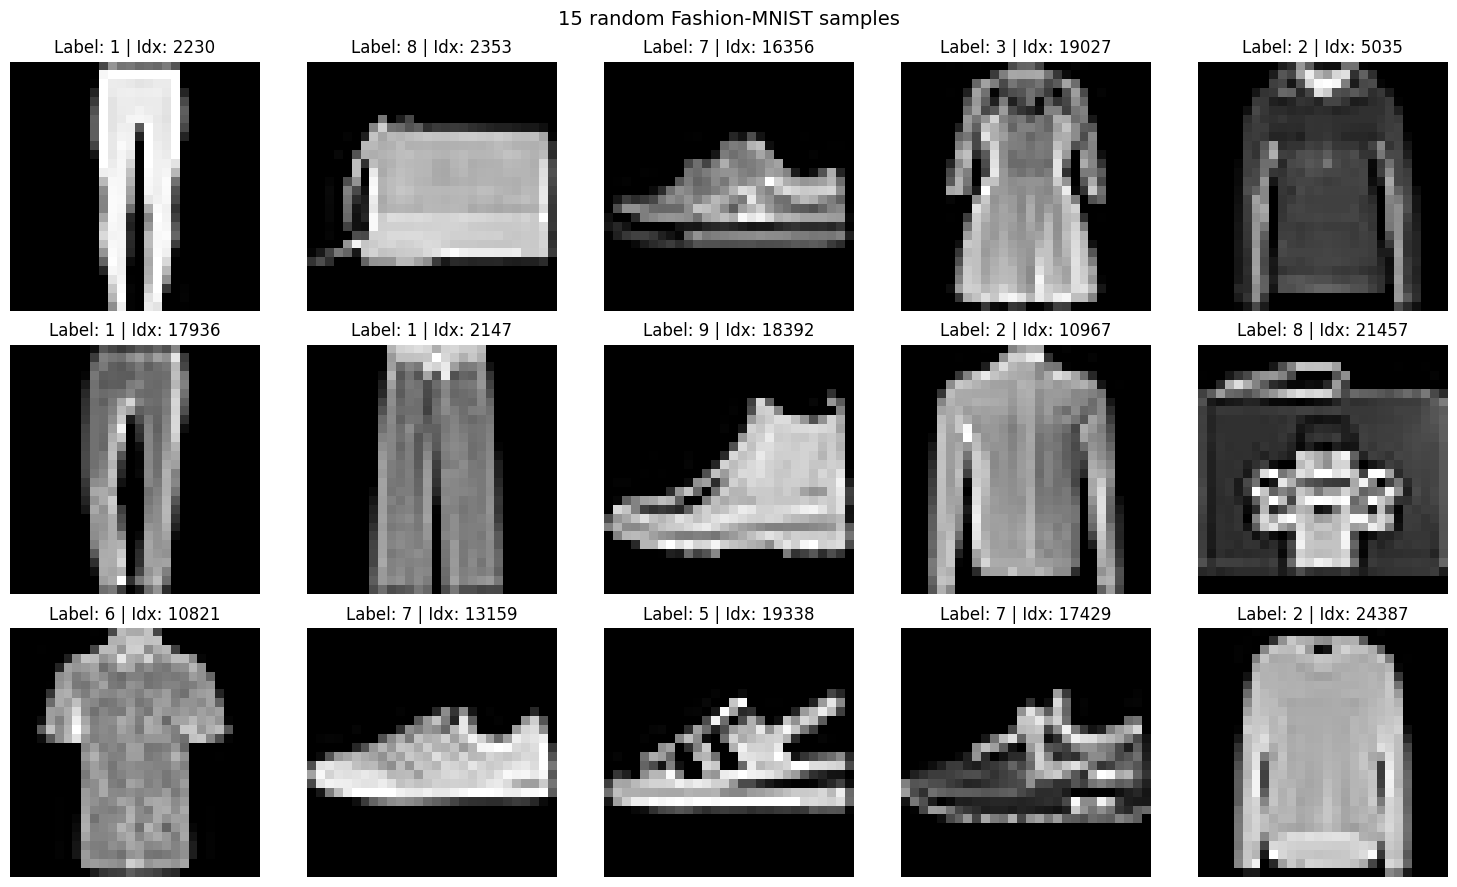

In [11]:
plot_random_15_images(
    X,
    y,
    random_state=42,
    save_path=FIGURES_PATH / "random_15_samples.png",
    show=True,
)

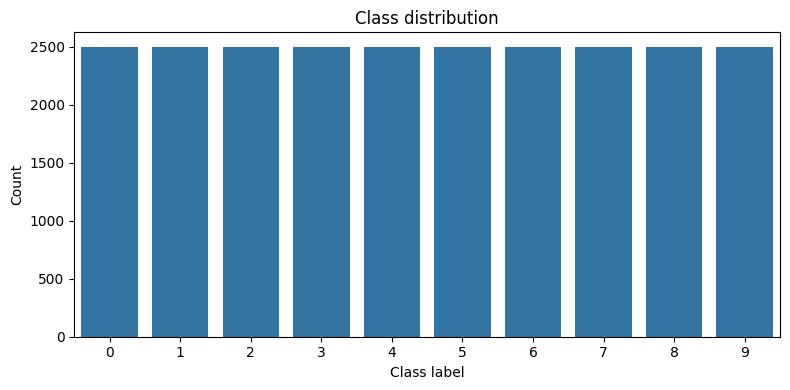

In [12]:
plot_class_distribution(
    y,
    save_path=FIGURES_PATH / "class_distribution.png",
    show=True,
)

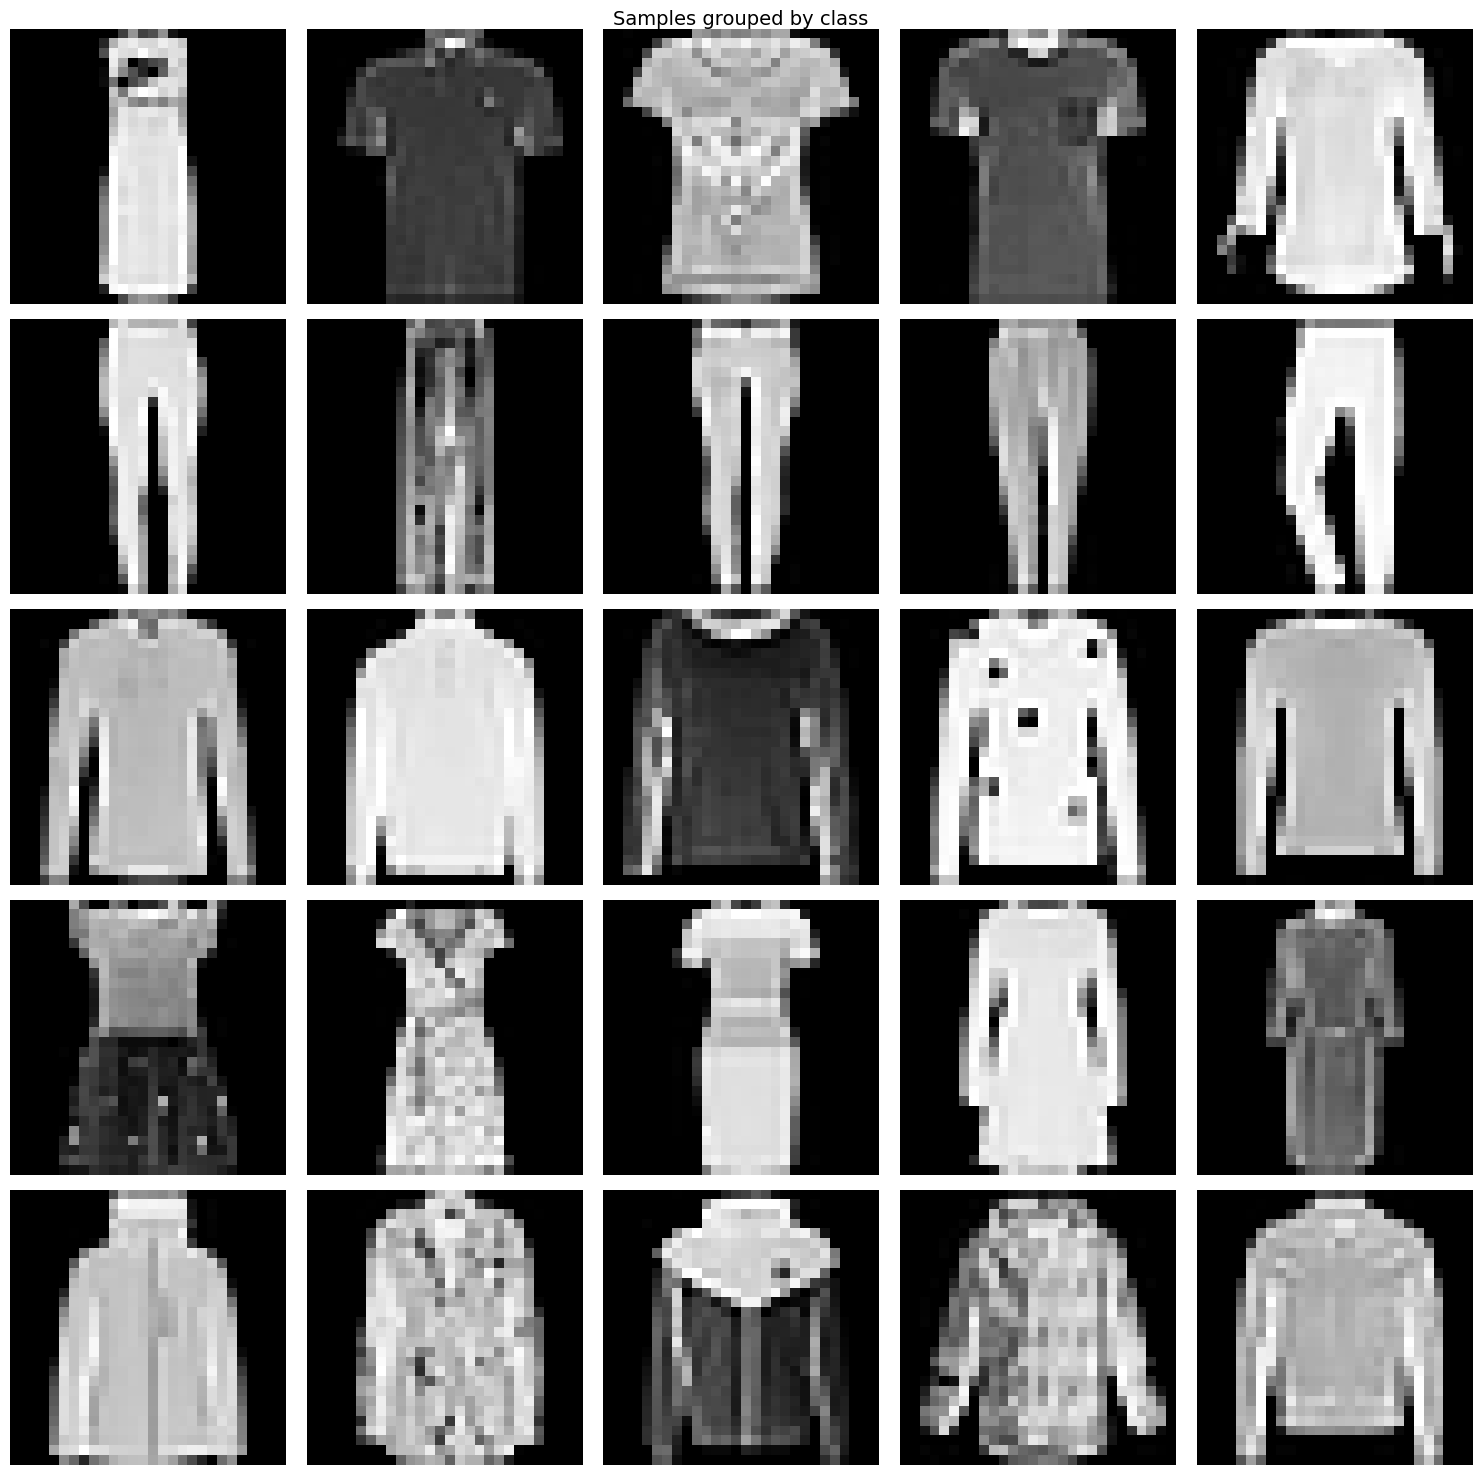

In [13]:
plot_images_by_class(
    X,
    y,
    classes=[0, 1, 2, 3, 4],
    samples_per_class=5,
    random_state=42,
    save_path=FIGURES_PATH / "samples_by_class.png",
    show=True,
)

In [14]:
X_train, X_test, y_train, y_test, train_idx, test_idx = stratified_train_test_split(
    X,
    y,
    train_size=0.8,
    random_state=42,
    return_indices=True,
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("train_idx:", train_idx.shape)
print("test_idx:", test_idx.shape)

X_train: (20000, 784)
X_test: (5000, 784)
train_idx: (20000,)
test_idx: (5000,)


In [15]:
split_dist_df = compare_split_distribution(y, y_train, y_test)
split_dist_df

,label,full_count,train_count,test_count,full_prop,train_prop,test_prop
0,0,2500,2000,500,0.1,0.1,0.1
1,1,2500,2000,500,0.1,0.1,0.1
2,2,2500,2000,500,0.1,0.1,0.1
3,3,2500,2000,500,0.1,0.1,0.1
4,4,2500,2000,500,0.1,0.1,0.1
5,5,2500,2000,500,0.1,0.1,0.1
6,6,2500,2000,500,0.1,0.1,0.1
7,7,2500,2000,500,0.1,0.1,0.1
8,8,2500,2000,500,0.1,0.1,0.1
9,9,2500,2000,500,0.1,0.1,0.1


In [16]:
X_sample, y_sample, sample_idx = stratified_sample(
    X_train,
    y_train,
    n_samples=3000,
    random_state=42,
    return_indices=True,
)

print("X_sample:", X_sample.shape)
print("y_sample:", y_sample.shape)
print("sample_idx:", sample_idx.shape)

X_sample: (3000, 784)
y_sample: (3000,)
sample_idx: (3000,)


In [17]:
standardizer_mean, standardizer_std = fit_standardizer(X_train)

X_train_scaled = transform_standardizer(X_train, standardizer_mean, standardizer_std)
X_test_scaled = transform_standardizer(X_test, standardizer_mean, standardizer_std)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)
print("Train scaled mean range:", X_train_scaled.mean(axis=0).min(), X_train_scaled.mean(axis=0).max())
print("Train scaled std range:", X_train_scaled.std(axis=0).min(), X_train_scaled.std(axis=0).max())

X_train_scaled: (20000, 784)
X_test_scaled: (5000, 784)
Train scaled mean range: -8.672498e-06 1.2351137e-05
Train scaled std range: 0.9997919 1.000204


# 2. Reducción de dimensionalidad

In [42]:
pca_result = fit_pca(X_train_scaled, center=False)

components = pca_result["components"]
eigenvalues = pca_result["eigenvalues"]
singular_values = pca_result["singular_values"]
explained_variance_ratio = pca_result["explained_variance_ratio"]
cumulative_explained_variance = pca_result["cumulative_explained_variance"]

print("Components shape:", components.shape)
print("Explained variance ratio shape:", explained_variance_ratio.shape)
print("Last cumulative explained variance:", cumulative_explained_variance[-1])

Components shape: (784, 784)
Explained variance ratio shape: (784,)
Last cumulative explained variance: 1.0000001


In [43]:
pca_variance_df = make_pca_variance_table(
    explained_variance_ratio,
    cumulative_explained_variance,
)

pca_variance_df.to_csv(TABLES_PATH / "pca_explained_variance.csv", index=False)
pca_variance_df.head()
K_PCA_90 = select_n_components(
    cumulative_explained_variance,
    threshold=0.90,
)

print(f"Number of PCA components for 90% explained variance: {K_PCA_90}")

Number of PCA components for 90% explained variance: 134


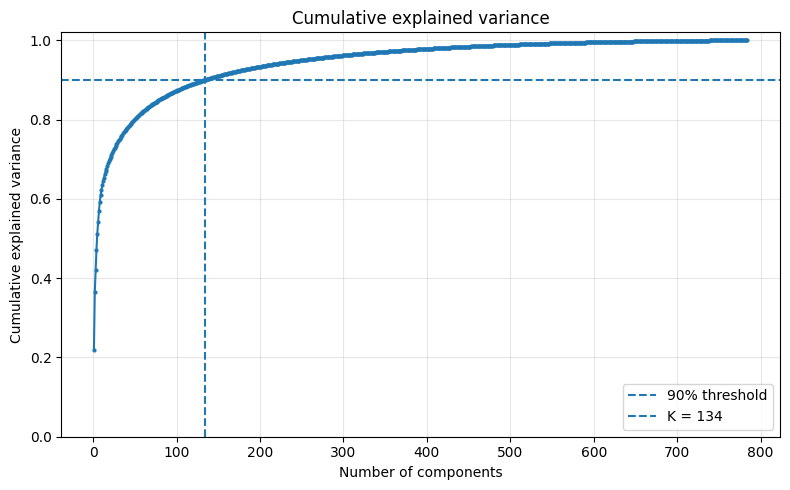

In [44]:
plot_cumulative_explained_variance(
    cumulative_explained_variance,
    threshold=0.90,
    n_components_selected=K_PCA_90,
    save_path=FIGURES_PATH / "pca_cumulative_explained_variance.png",
    show=True,
)

In [45]:
Z_train_pca = transform_pca(
    X_train_scaled,
    components,
    n_components=K_PCA_90,
)

Z_test_pca = transform_pca(
    X_test_scaled,
    components,
    n_components=K_PCA_90,
)

print("Z_train_pca:", Z_train_pca.shape)
print("Z_test_pca:", Z_test_pca.shape)

Z_train_pca: (20000, 134)
Z_test_pca: (5000, 134)


In [46]:
components_k = components[:K_PCA_90]

X_test_scaled_reconstructed_pca = inverse_transform_pca(
    Z_test_pca,
    components_k,
)

X_test_reconstructed_pca = inverse_transform_standardizer(
    X_test_scaled_reconstructed_pca,
    standardizer_mean,
    standardizer_std,
)

X_test_reconstructed_pca = np.clip(X_test_reconstructed_pca, 0, 1)
np.save(TABLES_PATH / "X_test_reconstructed_pca.npy", X_test_reconstructed_pca)

print("X_test_reconstructed_pca:", X_test_reconstructed_pca.shape)

pca_test_mse = reconstruction_mse(
    X_test,
    X_test_reconstructed_pca,
)

print(f"PCA test reconstruction MSE: {pca_test_mse:.6f}")

X_test_reconstructed_pca: (5000, 784)
PCA test reconstruction MSE: 0.007781


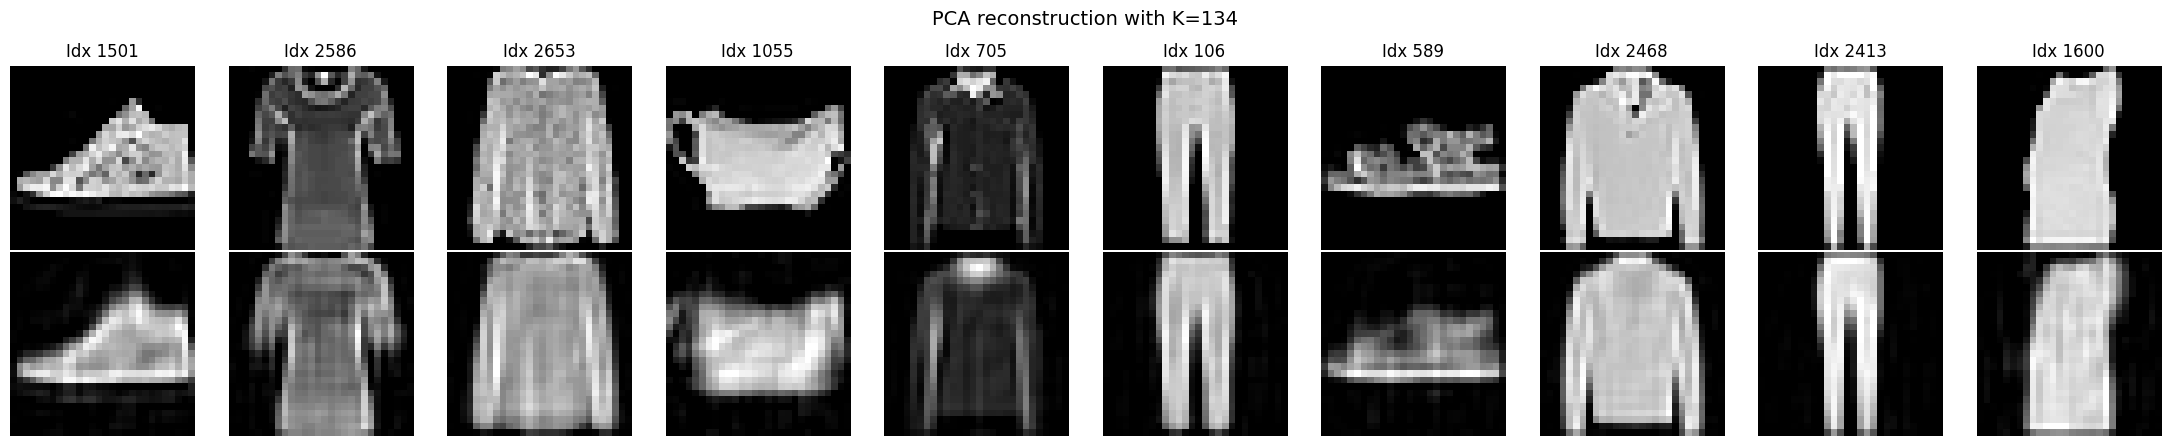

In [47]:
pca_reconstruction_indices = np.random.choice(X_test.shape[0], size=10, replace=False)

plot_original_vs_reconstructed(
    X_original=X_test,
    X_reconstructed=X_test_reconstructed_pca,
    indices=pca_reconstruction_indices,
    title=f"PCA reconstruction with K={K_PCA_90}",
    save_path=FIGURES_PATH / "pca_original_vs_reconstructed.png",
    show=True,
)

pca_config_df = pd.DataFrame(
    {
        "parameter": ["K_PCA_90", "pca_test_reconstruction_mse"],
        "value": [K_PCA_90, pca_test_mse],
    }
)

pca_config_df.to_csv(TABLES_PATH / "pca_config.csv", index=False)

## Autoencoder Determinístico

In [48]:
set_global_seed(42)

DEVICE = get_torch_device(prefer_gpu=True)

BATCH_SIZE = 256
N_EPOCHS = 100
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 0.0

INPUT_DIM = X_train.shape[1]
LATENT_DIM = K_PCA_90
HIDDEN_DIMS = (1024, 512)

In [49]:
train_loader_ae = create_autoencoder_dataloader(
    X_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_loader_ae = create_autoencoder_dataloader(
    X_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [50]:
ae_model = DeterministicAutoencoder(
    input_dim=INPUT_DIM,
    latent_dim=LATENT_DIM,
    hidden_dims=HIDDEN_DIMS,
)

ae_model

DeterministicAutoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=1024, bias=True)
    (1): ReLU()
    (2): Linear(in_features=1024, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=134, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=134, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=1024, bias=True)
    (3): ReLU()
    (4): Linear(in_features=1024, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [51]:
ae_history = train_autoencoder(
    model=ae_model,
    train_loader=train_loader_ae,
    val_loader=val_loader_ae,
    n_epochs=N_EPOCHS,
    learning_rate=LEARNING_RATE,
    device=DEVICE,
    weight_decay=WEIGHT_DECAY,
    verbose=True,
)

Epoch 001/100 | train_loss=0.063193 | val_loss=0.037751
Epoch 002/100 | train_loss=0.031467 | val_loss=0.025567
Epoch 003/100 | train_loss=0.023745 | val_loss=0.022444
Epoch 004/100 | train_loss=0.021412 | val_loss=0.020863
Epoch 005/100 | train_loss=0.019955 | val_loss=0.019429
Epoch 006/100 | train_loss=0.018336 | val_loss=0.017967
Epoch 007/100 | train_loss=0.017272 | val_loss=0.018376
Epoch 008/100 | train_loss=0.016537 | val_loss=0.016496
Epoch 009/100 | train_loss=0.015791 | val_loss=0.015750
Epoch 010/100 | train_loss=0.015255 | val_loss=0.015206
Epoch 011/100 | train_loss=0.014654 | val_loss=0.015226
Epoch 012/100 | train_loss=0.014209 | val_loss=0.014490
Epoch 013/100 | train_loss=0.013763 | val_loss=0.013988
Epoch 014/100 | train_loss=0.013372 | val_loss=0.013515
Epoch 015/100 | train_loss=0.013147 | val_loss=0.013408
Epoch 016/100 | train_loss=0.012673 | val_loss=0.013030
Epoch 017/100 | train_loss=0.012313 | val_loss=0.012819
Epoch 018/100 | train_loss=0.011957 | val_loss=0

In [52]:
ae_history_df = pd.DataFrame(ae_history)
ae_history_df.to_csv(TABLES_PATH / "ae_training_history.csv", index=False)

ae_history_df.tail()

,epoch,train_loss,val_loss
95,96,0.005317,0.007889
96,97,0.005276,0.007741
97,98,0.005233,0.007945
98,99,0.005274,0.007848
99,100,0.005274,0.007680


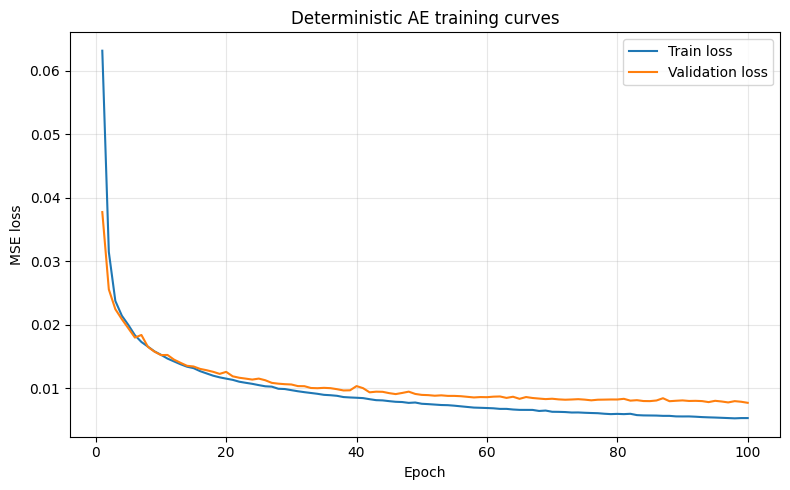

In [53]:
plot_training_curves(
    history=ae_history,
    title="Deterministic AE training curves",
    save_path=FIGURES_PATH / "ae_loss_curves.png",
    show=True,
)

In [54]:
X_test_reconstructed_ae = reconstruct_autoencoder(
    model=ae_model,
    X=X_test,
    batch_size=BATCH_SIZE,
    device=DEVICE,
)

X_test_reconstructed_ae = np.clip(X_test_reconstructed_ae, 0, 1)
np.save(TABLES_PATH / "X_test_reconstructed_ae.npy", X_test_reconstructed_ae)

print("X_test_reconstructed_ae:", X_test_reconstructed_ae.shape)

X_test_reconstructed_ae: (5000, 784)


In [55]:
ae_test_mse = reconstruction_mse(
    X_test,
    X_test_reconstructed_ae,
)

print(f"PCA test reconstruction MSE: {pca_test_mse:.6f}")
print(f"AE test reconstruction MSE: {ae_test_mse:.6f}")

PCA test reconstruction MSE: 0.007781
AE test reconstruction MSE: 0.007680


In [56]:
reconstruction_indices_path = TABLES_PATH / "reconstruction_indices.npy"

if reconstruction_indices_path.exists():
    reconstruction_indices = np.load(reconstruction_indices_path)
else:
    rng = np.random.default_rng(42)
    reconstruction_indices = rng.choice(
        X_test.shape[0],
        size=10,
        replace=False,
    )
    np.save(reconstruction_indices_path, reconstruction_indices)

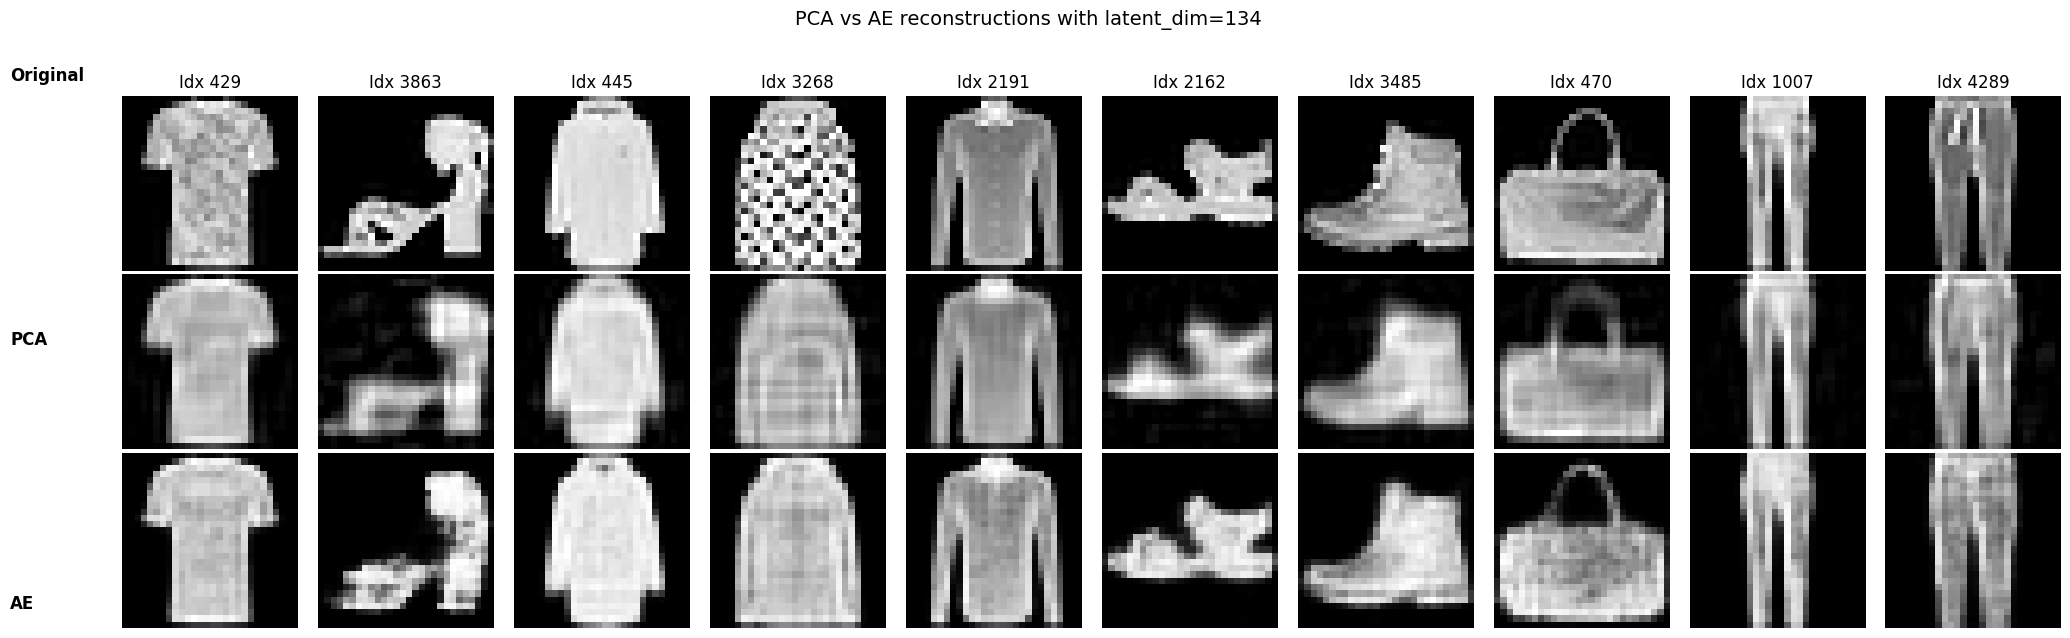

In [57]:
plot_multiple_reconstructions(
    X_original=X_test,
    reconstructions={
        "PCA": X_test_reconstructed_pca,
        "AE": X_test_reconstructed_ae,
    },
    indices=reconstruction_indices,
    title=f"PCA vs AE reconstructions with latent_dim={LATENT_DIM}",
    save_path=FIGURES_PATH / "pca_vs_ae_reconstructions.png",
    show=True,
)

In [58]:
ae_config = {
    "input_dim": INPUT_DIM,
    "latent_dim": LATENT_DIM,
    "hidden_dims": HIDDEN_DIMS,
    "batch_size": BATCH_SIZE,
    "n_epochs": N_EPOCHS,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
}

save_torch_model(
    model=ae_model,
    file_path=MODELS_PATH / "ae_model.pt",
    config=ae_config,
)

In [59]:
ae_config_df = pd.DataFrame(
    {
        "parameter": [
            "LATENT_DIM",
            "pca_test_mse",
            "ae_test_mse",
            "batch_size",
            "n_epochs",
            "learning_rate",
            "weight_decay",
            "hidden_dims",
        ],
        "value": [
            LATENT_DIM,
            pca_test_mse,
            ae_test_mse,
            BATCH_SIZE,
            N_EPOCHS,
            LEARNING_RATE,
            WEIGHT_DECAY,
            str(HIDDEN_DIMS),
        ],
    }
)

ae_config_df.to_csv(TABLES_PATH / "ae_config.csv", index=False)
ae_config_df

,parameter,value
0,LATENT_DIM,134
1,pca_test_mse,0.007781
2,ae_test_mse,0.00768
3,batch_size,256
4,n_epochs,100
5,learning_rate,0.001
6,weight_decay,0.0
7,hidden_dims,"(1024, 512)"


PCA minimiza óptimamente el error de reconstrucción lineal bajo MSE para una dimensión latente fija. El AE puede aprender representaciones no lineales y eventualmente superar a PCA, pero no está garantizado porque depende de una optimización no convexa, la arquitectura, los hiperparámetros y la convergencia. Si el MSE del AE es mayor que el de PCA, el resultado no invalida el modelo: puede indicar subentrenamiento, capacidad insuficiente, learning rate no óptimo o saturación de la salida Sigmoid.

In [60]:
Z_train_ae = encode_autoencoder(
    model=ae_model,
    X=X_train,
    batch_size=BATCH_SIZE,
    device=DEVICE,
)

Z_test_ae = encode_autoencoder(
    model=ae_model,
    X=X_test,
    batch_size=BATCH_SIZE,
    device=DEVICE,
)

print("Z_train_ae:", Z_train_ae.shape)
print("Z_test_ae:", Z_test_ae.shape)

Z_train_ae: (20000, 134)
Z_test_ae: (5000, 134)


In [61]:
np.save(TABLES_PATH / "Z_train_ae.npy", Z_train_ae)
np.save(TABLES_PATH / "Z_test_ae.npy", Z_test_ae)

## $\beta$-VAE

In [ ]:
set_global_seed(42)

DEVICE = get_torch_device(prefer_gpu=True)

BETA = 1.0
N_EPOCHS_VAE = 100
LEARNING_RATE_VAE = 1e-3
WEIGHT_DECAY_VAE = 0.0
BATCH_SIZE = 256

INPUT_DIM = X_train.shape[1]
LATENT_DIM = K_PCA_90
HIDDEN_DIMS_VAE = (512, 256)

In [19]:
train_loader_vae = create_autoencoder_dataloader(
    X_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
)

val_loader_vae = create_autoencoder_dataloader(
    X_test,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

In [20]:
vae_model = BetaVariationalAutoencoder(
    input_dim=INPUT_DIM,
    latent_dim=LATENT_DIM,
    hidden_dims=HIDDEN_DIMS_VAE,
)

vae_model

BetaVariationalAutoencoder(
  (encoder_backbone): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=256, bias=True)
    (3): ReLU()
  )
  (fc_mu): Linear(in_features=256, out_features=134, bias=True)
  (fc_logvar): Linear(in_features=256, out_features=134, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=134, out_features=256, bias=True)
    (1): ReLU()
    (2): Linear(in_features=256, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [38]:
beta_results = []

for beta_value in [0.1, 0.5, 1.0, 2.0]:
    set_global_seed(42)

    model_tmp = BetaVariationalAutoencoder(
        input_dim=INPUT_DIM,
        latent_dim=LATENT_DIM,
        hidden_dims=HIDDEN_DIMS_VAE,
    )

    history_tmp = train_beta_vae(
        model=model_tmp,
        train_loader=train_loader_vae,
        val_loader=val_loader_vae,
        n_epochs=100,
        learning_rate=LEARNING_RATE_VAE,
        beta=beta_value,
        device=DEVICE,
        weight_decay=WEIGHT_DECAY_VAE,
        verbose=False
    )

    X_test_rec_tmp = reconstruct_beta_vae(
        model=model_tmp,
        X=X_test,
        batch_size=BATCH_SIZE,
        device=DEVICE,
        deterministic=True,
    )

    X_test_rec_tmp = np.clip(X_test_rec_tmp, 0, 1)

    mse_tmp = reconstruction_mse(X_test, X_test_rec_tmp)

    beta_results.append(
        {
            "beta": beta_value,
            "epochs": len(history_tmp["epoch"]),
            "final_val_total_loss": history_tmp["val_total_loss"][-1],
            "final_val_reconstruction_loss": history_tmp["val_reconstruction_loss"][-1],
            "final_val_kl_loss": history_tmp["val_kl_loss"][-1],
            "vae_test_mse": mse_tmp,
        }
    )

beta_results_df = pd.DataFrame(beta_results)
beta_results_df.to_csv(TABLES_PATH / "vae_beta_sweep_results.csv", index=False)
beta_results_df

,beta,epochs,final_val_total_loss,final_val_reconstruction_loss,final_val_kl_loss,vae_test_mse
0,0.1,100,12.450671,10.166298,22.843733,0.012309
1,0.5,100,19.002024,13.636146,10.731756,0.015671
2,1.0,100,23.689186,16.028354,7.660832,0.017604
3,2.0,100,30.254859,19.978524,5.138167,0.021166


In [21]:
vae_history = train_beta_vae(
    model=vae_model,
    train_loader=train_loader_vae,
    val_loader=val_loader_vae,
    n_epochs=N_EPOCHS_VAE,
    learning_rate=LEARNING_RATE_VAE,
    beta=BETA,
    device=DEVICE,
    weight_decay=WEIGHT_DECAY_VAE,
    verbose=True,
)

Epoch 001/100 | train_total=67.433988 | train_rec_sse=65.417567 | train_rec_mse=0.041720 | train_kl=2.016421 | val_total=49.671828 | val_rec_sse=45.150571 | val_rec_mse=0.028795 | val_kl=4.521256
Epoch 002/100 | train_total=44.844766 | train_rec_sse=39.616882 | train_rec_mse=0.025266 | train_kl=5.227884 | val_total=43.047331 | val_rec_sse=37.352051 | val_rec_mse=0.023821 | val_kl=5.695280
Epoch 003/100 | train_total=42.509080 | train_rec_sse=36.752109 | train_rec_mse=0.023439 | train_kl=5.756971 | val_total=41.860594 | val_rec_sse=36.112461 | val_rec_mse=0.023031 | val_kl=5.748133
Epoch 004/100 | train_total=40.490160 | train_rec_sse=34.196209 | train_rec_mse=0.021809 | train_kl=6.293951 | val_total=38.940506 | val_rec_sse=32.261410 | val_rec_mse=0.020575 | val_kl=6.679096
Epoch 005/100 | train_total=37.755514 | train_rec_sse=30.870993 | train_rec_mse=0.019688 | train_kl=6.884521 | val_total=36.602075 | val_rec_sse=29.480614 | val_rec_mse=0.018801 | val_kl=7.121462
Epoch 006/100 | trai

In [23]:
vae_history_df = pd.DataFrame(vae_history)
vae_history_df.to_csv(TABLES_PATH / "vae_training_history.csv", index=False)

vae_history_df.tail()

,epoch,train_total_loss,train_reconstruction_loss,train_reconstruction_mse,train_kl_loss,val_total_loss,val_reconstruction_loss,val_reconstruction_mse,val_kl_loss
95,96,23.281925,15.713733,0.010022,7.568192,23.828191,16.155406,0.010303,7.672785
96,97,23.256979,15.678013,0.009999,7.578967,23.801176,16.189838,0.010325,7.611337
97,98,23.265518,15.693314,0.010008,7.572204,23.967452,16.423737,0.010474,7.543715
98,99,23.251033,15.689895,0.010006,7.561138,23.754258,16.091812,0.010263,7.662446
99,100,23.245984,15.686789,0.010004,7.559195,23.689186,16.028354,0.010222,7.660832


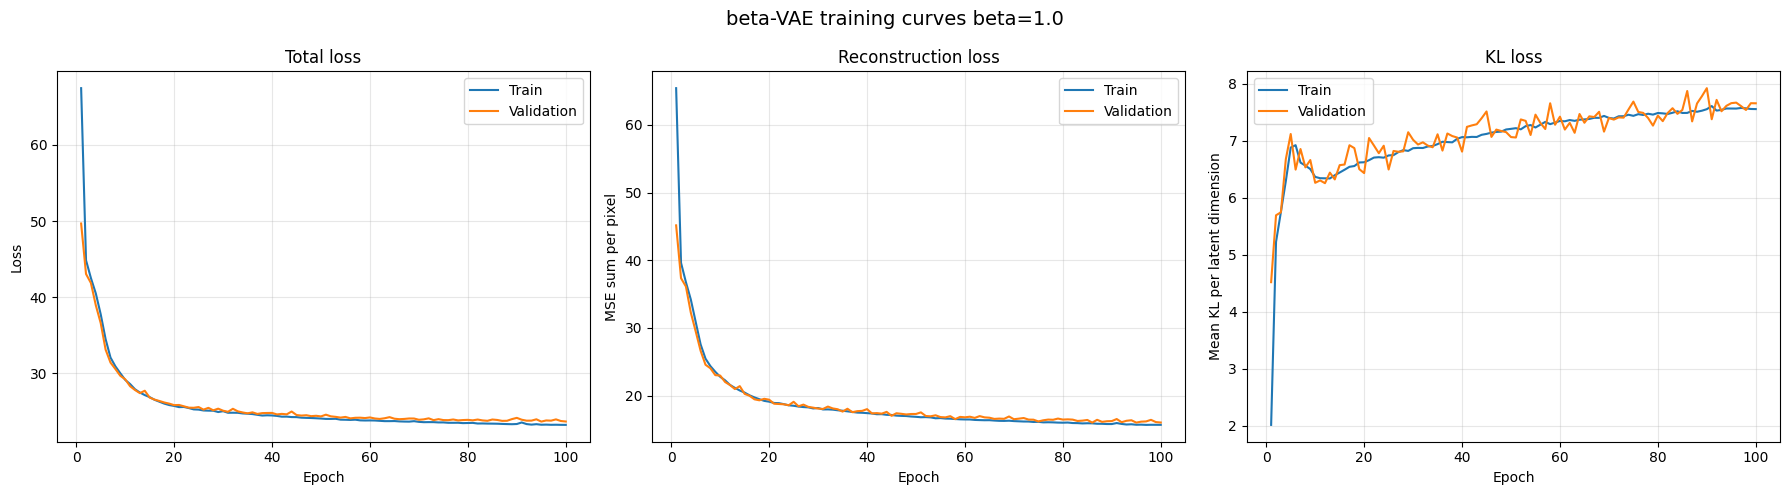

In [24]:
plot_vae_training_curves(
    history=vae_history,
    title=f"beta-VAE training curves beta={BETA}",
    save_path=FIGURES_PATH / "vae_loss_curves.png",
    show=True,
)

### Nota sobre la escala de las pérdidas del beta-VAE

El beta-VAE se entrena con una formulación tipo ELBO: la reconstrucción se calcula como suma de errores cuadrados por muestra, promediada sobre el batch, y el término KL también se promedia por muestra. Esta escala es adecuada para balancear reconstrucción y regularización latente durante el entrenamiento.

Para comparar contra PCA y AE, se registra además `reconstruction_mse`, que corresponde al MSE promedio por píxel. Esta métrica sí es comparable con `pca_test_mse`, `ae_test_mse` y `vae_test_mse`.

In [62]:
X_test_reconstructed_vae = reconstruct_beta_vae(
    model=vae_model,
    X=X_test,
    batch_size=BATCH_SIZE,
    device=DEVICE,
    deterministic=True,
)

X_test_reconstructed_vae = np.clip(X_test_reconstructed_vae, 0, 1)

vae_test_mse = reconstruction_mse(
    X_test,
    X_test_reconstructed_vae,
)

print(f"PCA test reconstruction MSE: {pca_test_mse:.6f}")
print(f"AE test reconstruction MSE: {ae_test_mse:.6f}")
print(f"beta-VAE test reconstruction MSE: {vae_test_mse:.6f}")

np.save(TABLES_PATH / "X_test_reconstructed_vae.npy", X_test_reconstructed_vae)

PCA test reconstruction MSE: 0.007781
AE test reconstruction MSE: 0.007680
beta-VAE test reconstruction MSE: 0.017604


In [28]:
reconstruction_indices_path = TABLES_PATH / "reconstruction_indices.npy"

if reconstruction_indices_path.exists():
    reconstruction_indices = np.load(reconstruction_indices_path)
else:
    rng = np.random.default_rng(42)
    reconstruction_indices = rng.choice(
        X_test.shape[0],
        size=10,
        replace=False,
    )
    np.save(reconstruction_indices_path, reconstruction_indices)

print("Reconstruction indices:", reconstruction_indices)

Reconstruction indices: [ 429 3863  445 3268 2191 2162 3485  470 1007 4289]


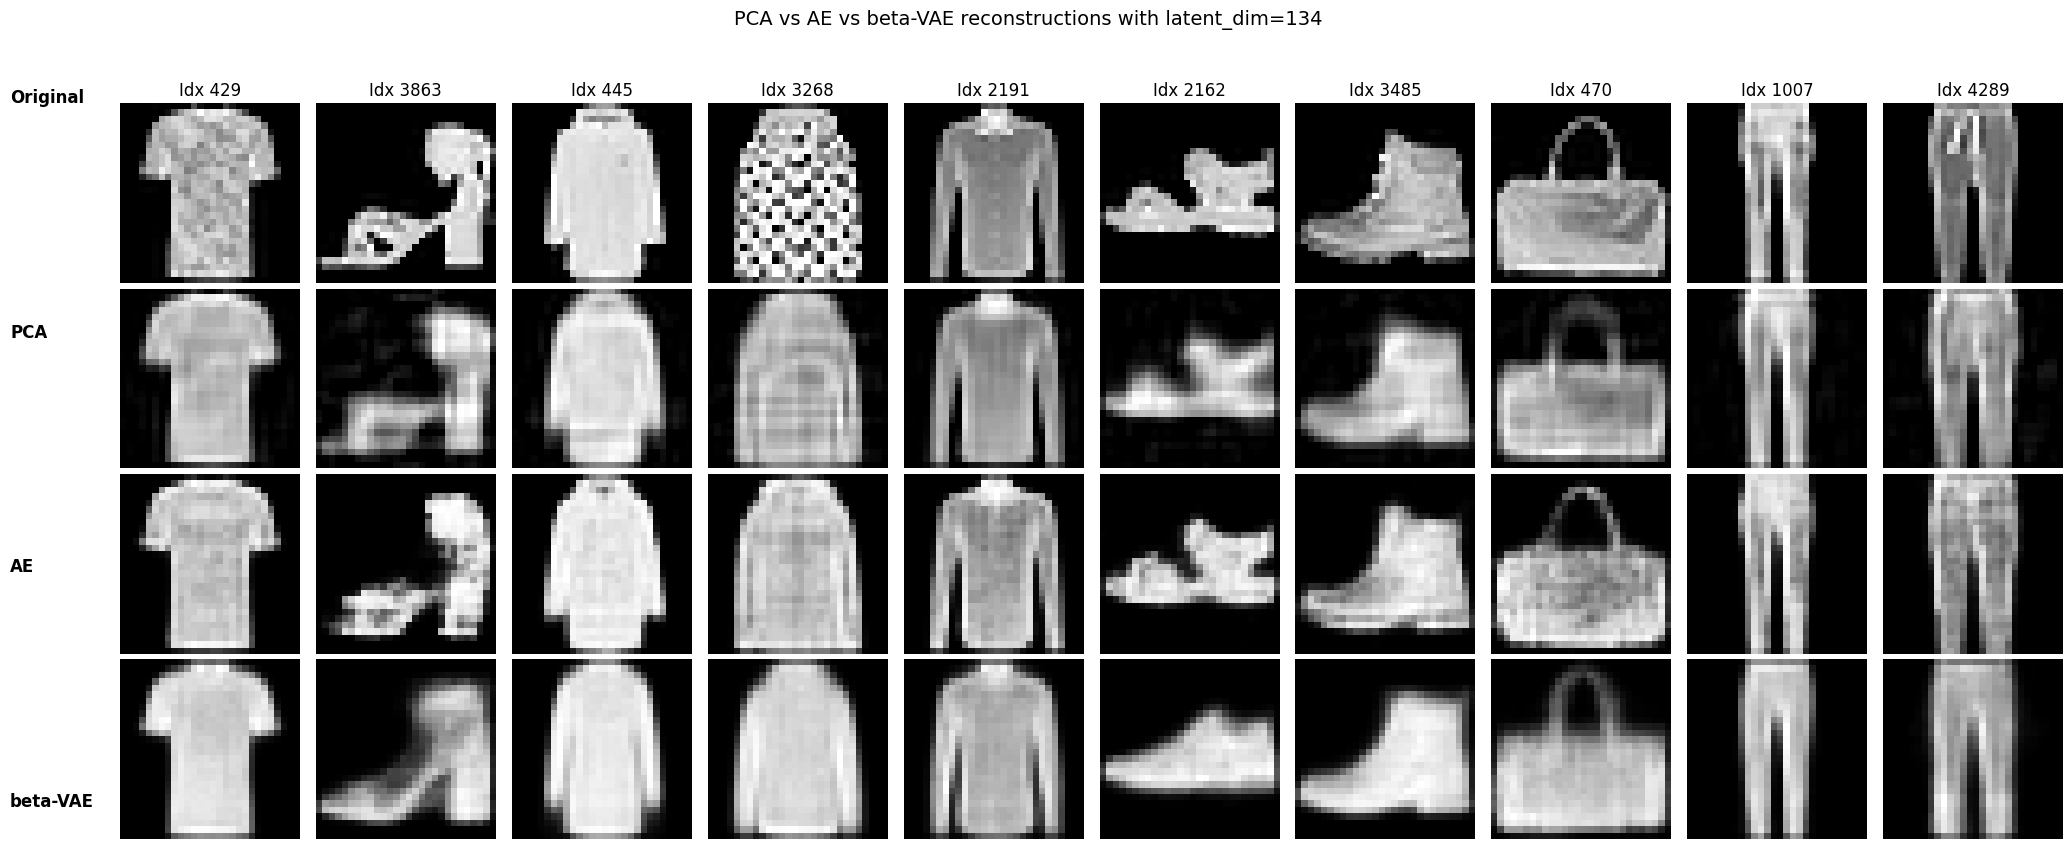

In [63]:
plot_multiple_reconstructions(
    X_original=X_test,
    reconstructions={
        "PCA": X_test_reconstructed_pca,
        "AE": X_test_reconstructed_ae,
        "beta-VAE": X_test_reconstructed_vae,
    },
    indices=reconstruction_indices,
    title=f"PCA vs AE vs beta-VAE reconstructions with latent_dim={LATENT_DIM}",
    save_path=FIGURES_PATH / "pca_ae_vae_reconstructions.png",
    show=True,
)

In [33]:
vae_config = {
    "input_dim": INPUT_DIM,
    "latent_dim": LATENT_DIM,
    "hidden_dims": HIDDEN_DIMS_VAE,
    "beta": BETA,
    "batch_size": BATCH_SIZE,
    "n_epochs": N_EPOCHS_VAE,
    "learning_rate": LEARNING_RATE_VAE,
    "weight_decay": WEIGHT_DECAY_VAE,
}

save_torch_model(
    model=vae_model,
    file_path=MODELS_PATH / "vae_model.pt",
    config=vae_config,
)

In [64]:
vae_config_df = pd.DataFrame(
    {
        "parameter": [
            "LATENT_DIM",
            "BETA",
            "pca_test_mse",
            "ae_test_mse",
            "vae_test_mse",
            "batch_size",
            "n_epochs",
            "learning_rate",
            "weight_decay",
            "hidden_dims",
        ],
        "value": [
            LATENT_DIM,
            BETA,
            pca_test_mse,
            ae_test_mse,
            vae_test_mse,
            BATCH_SIZE,
            N_EPOCHS_VAE,
            LEARNING_RATE_VAE,
            WEIGHT_DECAY_VAE,
            str(HIDDEN_DIMS_VAE),
        ],
    }
)

vae_config_df.to_csv(TABLES_PATH / "vae_config.csv", index=False)
vae_config_df

,parameter,value
0,LATENT_DIM,134
1,BETA,1.0
2,pca_test_mse,0.007781
3,ae_test_mse,0.00768
4,vae_test_mse,0.017604
5,batch_size,256
6,n_epochs,100
7,learning_rate,0.001
8,weight_decay,0.0
9,hidden_dims,"(512, 256)"


In [35]:
Z_train_vae_mu = encode_beta_vae(
    model=vae_model,
    X=X_train,
    batch_size=BATCH_SIZE,
    device=DEVICE,
    return_logvar=False,
)

Z_test_vae_mu = encode_beta_vae(
    model=vae_model,
    X=X_test,
    batch_size=BATCH_SIZE,
    device=DEVICE,
    return_logvar=False,
)

print("Z_train_vae_mu:", Z_train_vae_mu.shape)
print("Z_test_vae_mu:", Z_test_vae_mu.shape)

np.save(TABLES_PATH / "Z_train_vae_mu.npy", Z_train_vae_mu)
np.save(TABLES_PATH / "Z_test_vae_mu.npy", Z_test_vae_mu)

Z_train_vae_mu: (20000, 134)
Z_test_vae_mu: (5000, 134)


In [36]:
rng = np.random.default_rng(42)

labels, counts = np.unique(y_test, return_counts=True)
valid_classes = labels[counts >= 4]

target_class = valid_classes[0]

same_class_pool = np.where(y_test == target_class)[0]
same_class_indices = rng.choice(
    same_class_pool,
    size=4,
    replace=False,
)

X_same_class = X_test[same_class_indices]

print("Target class:", target_class)
print("Selected indices:", same_class_indices)

Target class: 0
Selected indices: [2156  406 3182 3659]


In [65]:
Z_same_class_ae = encode_autoencoder(
    model=ae_model,
    X=X_same_class,
    batch_size=BATCH_SIZE,
    device=DEVICE,
)

Z_average_ae = Z_same_class_ae.mean(axis=0, keepdims=True)

X_average_decoded_ae = decode_autoencoder(
    model=ae_model,
    Z=Z_average_ae,
    batch_size=BATCH_SIZE,
    device=DEVICE,
)

X_average_decoded_ae = np.clip(X_average_decoded_ae, 0, 1)

In [66]:
Z_same_class_vae_mu = encode_beta_vae(
    model=vae_model,
    X=X_same_class,
    batch_size=BATCH_SIZE,
    device=DEVICE,
    return_logvar=False,
)

Z_average_vae_mu = Z_same_class_vae_mu.mean(axis=0, keepdims=True)

X_average_decoded_vae = decode_beta_vae(
    model=vae_model,
    Z=Z_average_vae_mu,
    batch_size=BATCH_SIZE,
    device=DEVICE,
)

X_average_decoded_vae = np.clip(X_average_decoded_vae, 0, 1)

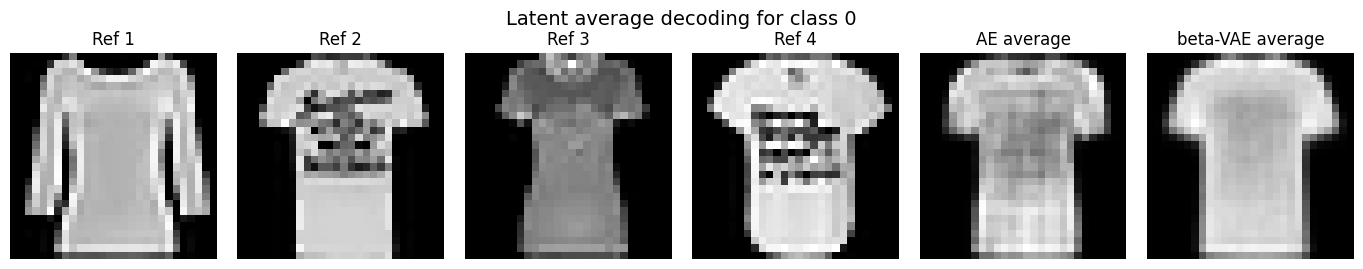

In [67]:
plot_latent_average_comparison(
    X_reference=X_same_class,
    decoded_images={
        "AE average": X_average_decoded_ae,
        "beta-VAE average": X_average_decoded_vae,
    },
    title=f"Latent average decoding for class {target_class}",
    save_path=FIGURES_PATH / "latent_average_ae_vs_vae.png",
    show=True,
)

In [68]:
rng = np.random.default_rng(42)

Z_random = rng.normal(
    loc=0.0,
    scale=1.0,
    size=(10, LATENT_DIM),
).astype(np.float32)

X_random_decoded_ae = decode_autoencoder(
    model=ae_model,
    Z=Z_random,
    batch_size=BATCH_SIZE,
    device=DEVICE,
)

X_random_decoded_vae = decode_beta_vae(
    model=vae_model,
    Z=Z_random,
    batch_size=BATCH_SIZE,
    device=DEVICE,
)

X_random_decoded_ae = np.clip(X_random_decoded_ae, 0, 1)
X_random_decoded_vae = np.clip(X_random_decoded_vae, 0, 1)

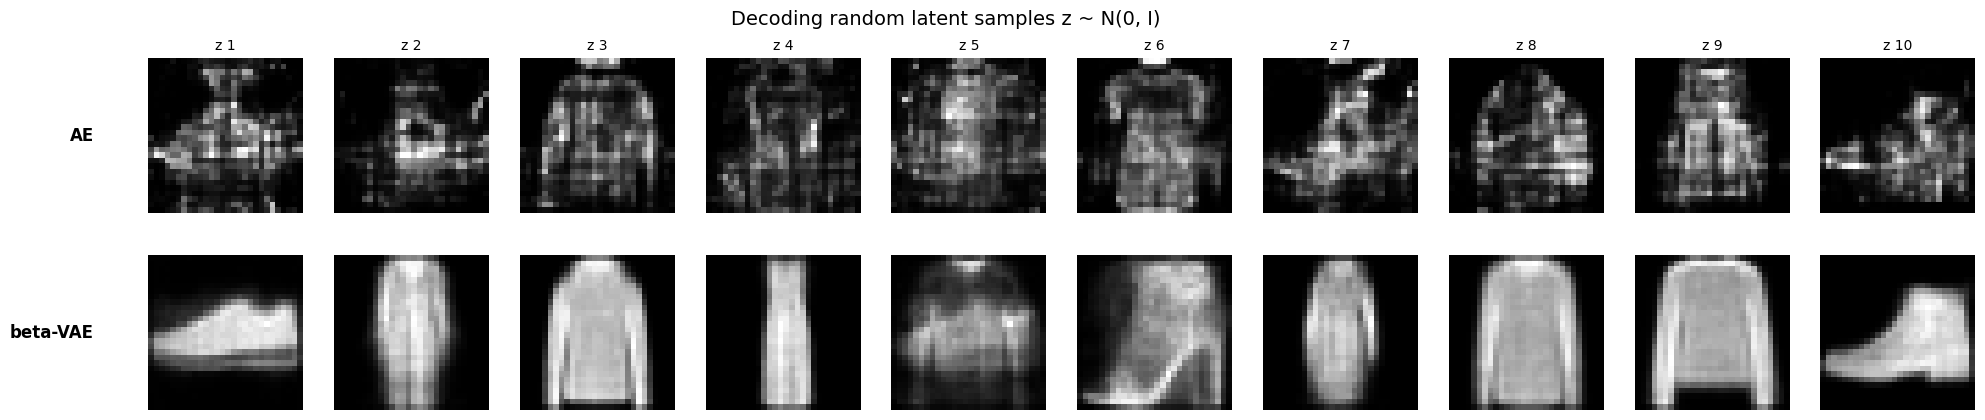

In [69]:
plot_random_latent_samples_comparison(
    decoded_samples={
        "AE": X_random_decoded_ae,
        "beta-VAE": X_random_decoded_vae,
    },
    n_images=10,
    title="Decoding random latent samples z ~ N(0, I)",
    save_path=FIGURES_PATH / "random_latent_sampling_ae_vs_vae.png",
    show=True,
)

# 3. Clustering

In [70]:
# For clustering, assembling train and test is not considered leakage here
# because clustering is used as an exploratory analysis over learned representations.
Z_all_pca = np.vstack([Z_train_pca, Z_test_pca])
Z_all_ae = np.vstack([Z_train_ae, Z_test_ae])
y_all = np.concatenate([y_train, y_test])

In [71]:
CLUSTERING_SAMPLE_SIZE = 3000

clustering_sample_indices = stratified_sample_indices(
    y=y_all,
    n_samples=CLUSTERING_SAMPLE_SIZE,
    random_state=42,
)

np.save(TABLES_PATH / "clustering_sample_indices.npy", clustering_sample_indices)

Z_sample_pca = Z_all_pca[clustering_sample_indices]
Z_sample_ae = Z_all_ae[clustering_sample_indices]
y_sample = y_all[clustering_sample_indices]

print("Z_sample_pca:", Z_sample_pca.shape)
print("Z_sample_ae:", Z_sample_ae.shape)
print("y_sample:", y_sample.shape)

Z_sample_pca: (3000, 134)
Z_sample_ae: (3000, 134)
y_sample: (3000,)


In [72]:
USE_LATENT_STANDARDIZATION = True

if USE_LATENT_STANDARDIZATION:
    pca_latent_mean, pca_latent_std = fit_standardizer(Z_sample_pca)
    ae_latent_mean, ae_latent_std = fit_standardizer(Z_sample_ae)

    Z_sample_pca_clust = transform_standardizer(
        Z_sample_pca,
        pca_latent_mean,
        pca_latent_std,
    )

    Z_sample_ae_clust = transform_standardizer(
        Z_sample_ae,
        ae_latent_mean,
        ae_latent_std,
    )
else:
    Z_sample_pca_clust = Z_sample_pca
    Z_sample_ae_clust = Z_sample_ae

In [73]:
D_sample_pca = pairwise_distances(Z_sample_pca_clust)
D_sample_ae = pairwise_distances(Z_sample_ae_clust)

latent_spaces = {
    "PCA": {
        "Z": Z_sample_pca_clust,
        "D": D_sample_pca,
    },
    "AE": {
        "Z": Z_sample_ae_clust,
        "D": D_sample_ae,
    },
}

In [74]:
K_VALUES = list(range(5, 16))

metrics_rows = []
labels_store = {}

for space_name, data in latent_spaces.items():
    Z_space = data["Z"]
    D_space = data["D"]

    for K in K_VALUES:
        print(f"Running k-Means | space={space_name} | K={K}")

        model = KMeansCustom(
            n_clusters=K,
            max_iter=100,
            tol=1e-4,
            random_state=42,
            init="kmeans++",
        )

        labels = model.fit_predict(Z_space)

        sil_score = silhouette_score_custom(
            labels=labels,
            distances=D_space,
        )

        purity = overall_purity(labels, y_sample)

        labels_store[("kmeans", space_name, K)] = labels

        metrics_rows.append(
            {
                "model": "kmeans",
                "space": space_name,
                "K": K,
                "inertia": model.inertia_,
                "log_likelihood": np.nan,
                "negative_log_likelihood": np.nan,
                "silhouette_score": sil_score,
                "purity": purity,
                "n_iter": model.n_iter_,
            }
        )

Running k-Means | space=PCA | K=5
Running k-Means | space=PCA | K=6
Running k-Means | space=PCA | K=7
Running k-Means | space=PCA | K=8
Running k-Means | space=PCA | K=9
Running k-Means | space=PCA | K=10
Running k-Means | space=PCA | K=11
Running k-Means | space=PCA | K=12
Running k-Means | space=PCA | K=13
Running k-Means | space=PCA | K=14
Running k-Means | space=PCA | K=15
Running k-Means | space=AE | K=5
Running k-Means | space=AE | K=6
Running k-Means | space=AE | K=7
Running k-Means | space=AE | K=8
Running k-Means | space=AE | K=9
Running k-Means | space=AE | K=10
Running k-Means | space=AE | K=11
Running k-Means | space=AE | K=12
Running k-Means | space=AE | K=13
Running k-Means | space=AE | K=14
Running k-Means | space=AE | K=15


In [75]:
for space_name, data in latent_spaces.items():
    Z_space = data["Z"]
    D_space = data["D"]

    for K in K_VALUES:
        print(f"Running GMM | space={space_name} | K={K}")

        model = GaussianMixtureCustom(
            n_components=K,
            covariance_type="diag",
            max_iter=100,
            tol=1e-4,
            reg_covar=1e-6,
            random_state=42,
            init_params="kmeans",
        )

        labels = model.fit_predict(Z_space)

        final_log_likelihood = model.log_likelihood_history_[-1]
        negative_log_likelihood = -final_log_likelihood

        sil_score = silhouette_score_custom(
            labels=labels,
            distances=D_space,
        )

        purity = overall_purity(labels, y_sample)

        labels_store[("gmm", space_name, K)] = labels

        metrics_rows.append(
            {
                "model": "gmm",
                "space": space_name,
                "K": K,
                "inertia": np.nan,
                "log_likelihood": final_log_likelihood,
                "negative_log_likelihood": negative_log_likelihood,
                "silhouette_score": sil_score,
                "purity": purity,
                "n_iter": model.n_iter_,
            }
        )

Running GMM | space=PCA | K=5
Running GMM | space=PCA | K=6
Running GMM | space=PCA | K=7
Running GMM | space=PCA | K=8
Running GMM | space=PCA | K=9
Running GMM | space=PCA | K=10
Running GMM | space=PCA | K=11
Running GMM | space=PCA | K=12
Running GMM | space=PCA | K=13
Running GMM | space=PCA | K=14
Running GMM | space=PCA | K=15
Running GMM | space=AE | K=5
Running GMM | space=AE | K=6
Running GMM | space=AE | K=7
Running GMM | space=AE | K=8
Running GMM | space=AE | K=9
Running GMM | space=AE | K=10
Running GMM | space=AE | K=11
Running GMM | space=AE | K=12
Running GMM | space=AE | K=13
Running GMM | space=AE | K=14
Running GMM | space=AE | K=15


In [76]:
clustering_metrics_df = pd.DataFrame(metrics_rows)

kmeans_df = clustering_metrics_df[clustering_metrics_df["model"] == "kmeans"]
gmm_df = clustering_metrics_df[clustering_metrics_df["model"] == "gmm"]

kmeans_df = add_marginal_gain(
    metrics_df=kmeans_df,
    group_cols=["model", "space"],
    metric_col="inertia",
    mode="decrease",
    output_col="marginal_gain",
)

gmm_df = add_marginal_gain(
    metrics_df=gmm_df,
    group_cols=["model", "space"],
    metric_col="negative_log_likelihood",
    mode="decrease",
    output_col="marginal_gain",
)

clustering_metrics_df = pd.concat([kmeans_df, gmm_df], ignore_index=True)

clustering_metrics_df.to_csv(
    TABLES_PATH / "clustering_metrics.csv",
    index=False,
)

clustering_metrics_df.head()

,model,space,K,inertia,log_likelihood,negative_log_likelihood,silhouette_score,purity,n_iter,marginal_gain,marginal_gain_relative
0,kmeans,AE,5,293943.06250,NaN,NaN,0.136272,0.423000,20,NaN,NaN
1,kmeans,AE,6,282977.62500,NaN,NaN,0.090466,0.481000,35,10965.43750,0.037305
2,kmeans,AE,7,273038.78125,NaN,NaN,0.091018,0.481000,30,9938.84375,0.035122
3,kmeans,AE,8,265344.15625,NaN,NaN,0.095878,0.534333,34,7694.62500,0.028181
4,kmeans,AE,9,258363.03125,NaN,NaN,0.097543,0.583000,17,6981.12500,0.026310


In [77]:
clustering_summary_best_by_model_space = (
    clustering_metrics_df
    .sort_values("silhouette_score", ascending=False)
    .groupby(["model", "space"], as_index=False)
    .first()
)

clustering_summary_best_by_model_space = clustering_summary_best_by_model_space[
    [
        "model",
        "space",
        "K",
        "silhouette_score",
        "marginal_gain",
        "marginal_gain_relative",
        "purity",
    ]
].rename(
    columns={
        "K": "best_K_by_silhouette",
        "purity": "purity_informative_only",
    }
)

clustering_summary_best_by_model_space.to_csv(
    TABLES_PATH / "clustering_summary_best_by_model_space.csv",
    index=False,
)

clustering_summary_best_by_model_space

,model,space,best_K_by_silhouette,silhouette_score,marginal_gain,marginal_gain_relative,purity_informative_only
0,gmm,AE,5,0.113163,1.301494,0.009065,0.416333
1,gmm,PCA,5,0.007761,1.764749,0.010147,0.197000
2,kmeans,AE,5,0.136272,5393.046875,0.023105,0.423000
3,kmeans,PCA,5,0.034674,1930.562500,0.005225,0.157333


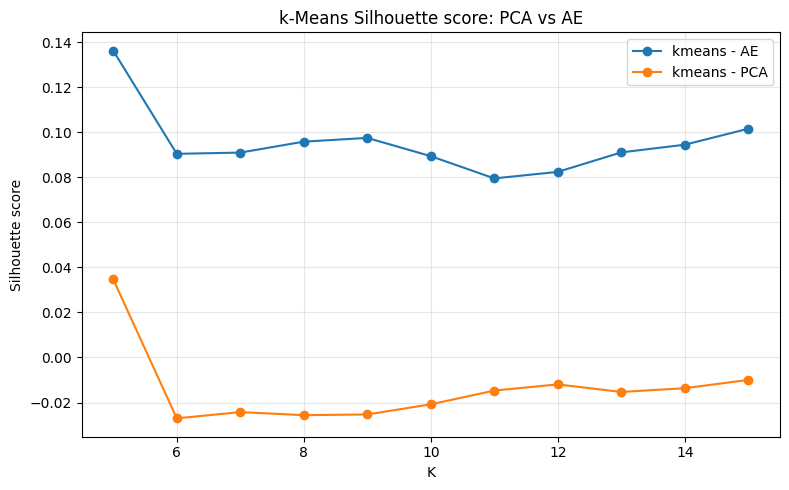

In [110]:
plot_silhouette_vs_k(
    clustering_metrics_df,
    model_name="kmeans",
    title="k-Means Silhouette score: PCA vs AE",
    save_path=FIGURES_PATH / "kmeans_silhouette_pca_vs_ae.png",
    show=True,
)

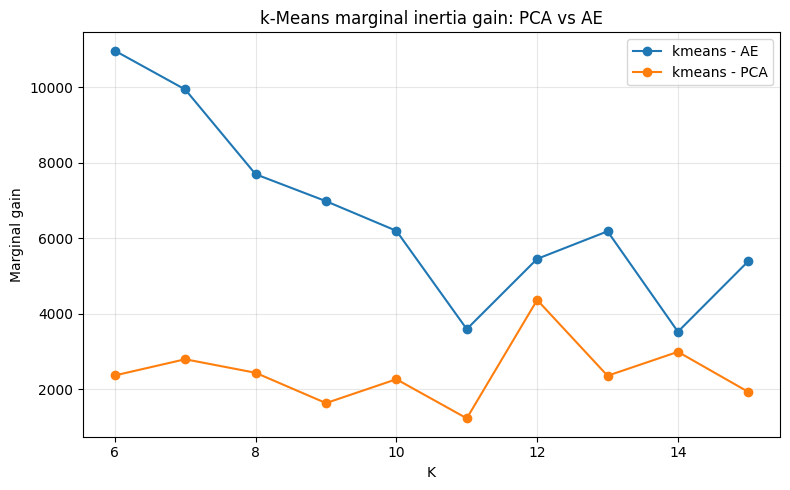

In [111]:
plot_marginal_gain_vs_k(
    clustering_metrics_df,
    model_name="kmeans",
    title="k-Means marginal inertia gain: PCA vs AE",
    save_path=FIGURES_PATH / "kmeans_gain_pca_vs_ae.png",
    show=True,
)

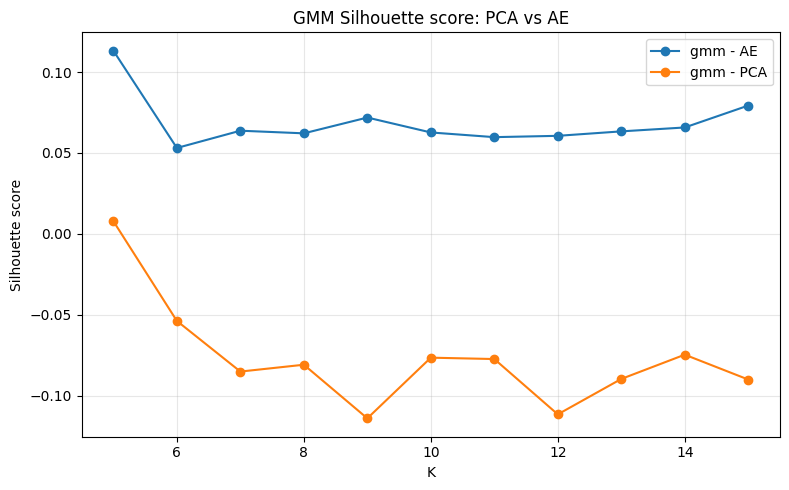

In [112]:
plot_silhouette_vs_k(
    clustering_metrics_df,
    model_name="gmm",
    title="GMM Silhouette score: PCA vs AE",
    save_path=FIGURES_PATH / "gmm_silhouette_pca_vs_ae.png",
    show=True,
)

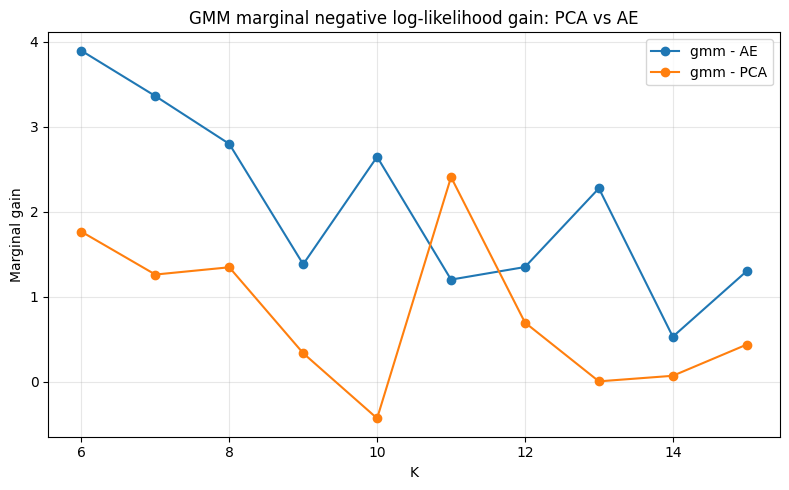

In [113]:
plot_marginal_gain_vs_k(
    clustering_metrics_df,
    model_name="gmm",
    title="GMM marginal negative log-likelihood gain: PCA vs AE",
    save_path=FIGURES_PATH / "gmm_gain_pca_vs_ae.png",
    show=True,
)

In [114]:
best_overall_by_silhouette = (
    clustering_metrics_df
    .sort_values("silhouette_score", ascending=False)
    .iloc[0]
)

best_pca_by_silhouette = (
    clustering_metrics_df[clustering_metrics_df["space"] == "PCA"]
    .sort_values("silhouette_score", ascending=False)
    .iloc[0]
)

print("Best overall by Silhouette:")
print(best_overall_by_silhouette[["model", "space", "K", "silhouette_score", "marginal_gain", "purity"]])

print("\nBest PCA by Silhouette:")
print(best_pca_by_silhouette[["model", "space", "K", "silhouette_score", "marginal_gain", "purity"]])

Best overall by Silhouette:
model                 kmeans
space                     AE
K                          5
silhouette_score    0.136272
marginal_gain            NaN
purity                 0.423
Name: 0, dtype: object

Best PCA by Silhouette:
model                 kmeans
space                    PCA
K                          5
silhouette_score    0.034674
marginal_gain            NaN
purity              0.157333
Name: 11, dtype: object


### Nota de marginal_gain
`Nan` representa aquellos casos en los que el primer cluster evaluado es aquel que fue seleccionado, por lo que no se puede registar una ganancia marginl.

In [115]:
BEST_OVERALL_MODEL_NAME = best_overall_by_silhouette["model"]
BEST_OVERALL_SPACE_NAME = best_overall_by_silhouette["space"]
BEST_OVERALL_K = int(best_overall_by_silhouette["K"])

BEST_PCA_MODEL_NAME = best_pca_by_silhouette["model"]
BEST_PCA_SPACE_NAME = best_pca_by_silhouette["space"]
BEST_PCA_K = int(best_pca_by_silhouette["K"])

best_overall_labels = labels_store[
    (BEST_OVERALL_MODEL_NAME, BEST_OVERALL_SPACE_NAME, BEST_OVERALL_K)
]

best_pca_labels = labels_store[
    (BEST_PCA_MODEL_NAME, BEST_PCA_SPACE_NAME, BEST_PCA_K)
]

np.save(TABLES_PATH / "best_overall_cluster_labels.npy", best_overall_labels)
np.save(TABLES_PATH / "best_pca_cluster_labels.npy", best_pca_labels)
np.save(TABLES_PATH / "clustering_sample_indices.npy", clustering_sample_indices)
np.save(TABLES_PATH / "Z_sample_pca_clust.npy", Z_sample_pca_clust)
np.save(TABLES_PATH / "Z_sample_ae_clust.npy", Z_sample_ae_clust)
np.save(TABLES_PATH / "y_sample_clustering.npy", y_sample)

print("Best overall:")
print("Model:", BEST_OVERALL_MODEL_NAME)
print("Space:", BEST_OVERALL_SPACE_NAME)
print("K:", BEST_OVERALL_K)

print("\nBest PCA:")
print("Model:", BEST_PCA_MODEL_NAME)
print("Space:", BEST_PCA_SPACE_NAME)
print("K:", BEST_PCA_K)

Best overall:
Model: kmeans
Space: AE
K: 5

Best PCA:
Model: kmeans
Space: PCA
K: 5


In [116]:
best_clustering_cases_df = pd.DataFrame(
    [
        {
            "case": "best_overall_by_silhouette",
            "model": BEST_OVERALL_MODEL_NAME,
            "space": BEST_OVERALL_SPACE_NAME,
            "K": BEST_OVERALL_K,
            "silhouette_score": best_overall_by_silhouette["silhouette_score"],
            "marginal_gain": best_overall_by_silhouette["marginal_gain"],
            "purity_informative_only": best_overall_by_silhouette["purity"],
        },
        {
            "case": "best_pca_by_silhouette",
            "model": BEST_PCA_MODEL_NAME,
            "space": BEST_PCA_SPACE_NAME,
            "K": BEST_PCA_K,
            "silhouette_score": best_pca_by_silhouette["silhouette_score"],
            "marginal_gain": best_pca_by_silhouette["marginal_gain"],
            "purity_informative_only": best_pca_by_silhouette["purity"],
        },
    ]
)

best_clustering_cases_df.to_csv(
    TABLES_PATH / "best_clustering_cases.csv",
    index=False,
)

best_clustering_cases_df

,case,model,space,K,silhouette_score,marginal_gain,purity_informative_only
0,best_overall_by_silhouette,kmeans,AE,5,0.136272,NaN,0.423000
1,best_pca_by_silhouette,kmeans,PCA,5,0.034674,NaN,0.157333


In [117]:
best_overall_cluster_size_df = cluster_size_table(best_overall_labels)
best_overall_cluster_class_df = cluster_class_table(best_overall_labels, y_sample)
best_overall_cluster_purity_df = cluster_purity_table(best_overall_labels, y_sample)

best_overall_cluster_size_df.to_csv(
    TABLES_PATH / "best_overall_cluster_size_table.csv",
    index=False,
)

best_overall_cluster_class_df.to_csv(
    TABLES_PATH / "best_overall_cluster_class_table.csv",
    index=False,
)

best_overall_cluster_purity_df.to_csv(
    TABLES_PATH / "best_overall_cluster_purity_table.csv",
    index=False,
)

best_overall_cluster_purity_df

,cluster,size,majority_class,majority_count,purity
0,0,627,1,284,0.452951
1,1,169,8,155,0.917160
2,2,1295,2,296,0.228571
3,3,467,9,288,0.616702
4,4,442,7,246,0.556561


In [118]:
best_pca_cluster_size_df = cluster_size_table(best_pca_labels)
best_pca_cluster_class_df = cluster_class_table(best_pca_labels, y_sample)
best_pca_cluster_purity_df = cluster_purity_table(best_pca_labels, y_sample)

best_pca_cluster_size_df.to_csv(
    TABLES_PATH / "best_pca_cluster_size_table.csv",
    index=False,
)

best_pca_cluster_class_df.to_csv(
    TABLES_PATH / "best_pca_cluster_class_table.csv",
    index=False,
)

best_pca_cluster_purity_df.to_csv(
    TABLES_PATH / "best_pca_cluster_purity_table.csv",
    index=False,
)

best_pca_cluster_purity_df

,cluster,size,majority_class,majority_count,purity
0,0,880,4,150,0.170455
1,1,13,8,5,0.384615
2,2,58,8,17,0.293103
3,3,2048,7,299,0.145996
4,4,1,8,1,1.000000


### Nota sobre el uso de purity

La métrica `purity` utiliza las etiquetas reales de clase, por lo tanto no debe usarse para seleccionar el mejor valor de `K` ni el mejor modelo de clustering. En este trabajo, la selección se basa en métricas no supervisadas, principalmente Silhouette score y análisis de ganancias marginales. La pureza se reporta únicamente como métrica interpretativa posterior para analizar la composición semántica de los clusters.

In [119]:
n_real_classes = len(np.unique(y_sample))

print("Real number of classes:", n_real_classes)

print("\nBest overall by Silhouette:")
print(f"K = {BEST_OVERALL_K}")

print("\nBest PCA by Silhouette:")
print(f"K = {BEST_PCA_K}")

print(
    "\nNote: K was selected using Silhouette score. "
    "Purity is reported only as an interpretative metric because it uses true labels."
)

Real number of classes: 10

Best overall by Silhouette:
K = 5

Best PCA by Silhouette:
K = 5

Note: K was selected using Silhouette score. Purity is reported only as an interpretative metric because it uses true labels.
